In [38]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [39]:
import nltk
from nltk.corpus import twitter_samples

nltk.download('twitter_samples')

all_positive_tweets = twitter_samples.strings('positive_tweets.json')
all_negative_tweets = twitter_samples.strings('negative_tweets.json')

all_positive_tweets = pd.DataFrame(all_positive_tweets)
all_positive_tweets['label'] = 1
all_negative_tweets = pd.DataFrame(all_negative_tweets)
all_negative_tweets['label'] = 0
df = pd.concat([all_positive_tweets,all_negative_tweets])

[nltk_data] Downloading package twitter_samples to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package twitter_samples is already up-to-date!


In [40]:
df

,0,label
0,#FollowFriday @France_Inte @PKuchly57 @Milipol...,1
1,@Lamb2ja Hey James! How odd :/ Please call our...,1
2,@DespiteOfficial we had a listen last night :)...,1
3,@97sides CONGRATS :),1
4,yeaaaah yippppy!!! my accnt verified rqst has...,1
...,...,...
4995,I wanna change my avi but uSanele :(,0
4996,MY PUPPY BROKE HER FOOT :(,0
4997,where's all the jaebum baby pictures :((,0
4998,But but Mr Ahmad Maslan cooks too :( https://t...,0


In [41]:
import re
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import TweetTokenizer

# Download the necessary NLTK resource packages if you don't have them
nltk.download('stopwords')

def process_tweet(tweet):
    """Process tweet function.
    Input:
        tweet: a string containing a tweet
    Output:
        tweets_clean: a list of words containing the processed tweet
    """
    stemmer = PorterStemmer()
    stopwords_english = stopwords.words('english')
    
    # 1. Remove old style retweet text "RT"
    tweet = re.sub(r'^RT[\s]+', '', tweet)

    # 2. Remove hyperlinks
    tweet = re.sub(r'https?:\/\/.*[\r\n]*', '', tweet)

    # 3. Remove hashtags (only removes the '#' sign, keeps the word text)
    tweet = re.sub(r'#', '', tweet)

    # 4. Remove stock market tickers like $GE
    tweet = re.sub(r'\$\w*', '', tweet)
    tweet = re.sub(r'<br />', '', tweet)

    # 5. Tokenize the tweet text
    tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
    tweet_tokens = tokenizer.tokenize(tweet)

    tweets_clean = []
    for word in tweet_tokens:
        if (word not in stopwords_english and  # Remove stopwords
            word not in string.punctuation):   # Remove punctuation marks
            
            # Stem the word and append to clean list
            stemmed_word = stemmer.stem(word)
            tweets_clean.append(stemmed_word)

    return tweets_clean

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [42]:
import numpy as np

def build_freqs(tweets, ys):
    """Build frequencies.
    Input:
        tweets: a list of tweets
        ys: an m x 1 array with the sentiment label of each tweet
            (either 0 or 1)
    Output:
        freqs: a dictionary mapping each (word, sentiment) pair to its
               frequency
    """
    # Convert np array to list since zip needs an iterable
    # squeeze removes single-dimensional entries from the shape of an array
    yslist = np.squeeze(ys).tolist()

    # Start with an empty dictionary
    freqs = {}
    
    # Iterate through all tweets and labels
    for y, tweet in zip(yslist, tweets):
        # Process the tweet to get a list of clean, stemmed words
        for word in process_tweet(tweet):
            # Define the key as a tuple: (word, label)
            pair = (word, y)
            
            # Update the count in the dictionary
            if pair in freqs:
                freqs[pair] += 1
            else:
                freqs[pair] = 1
                
    return freqs


In [43]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df[0],df['label'],random_state=42,test_size=0.33)

working with training data

In [44]:
new_df = pd.DataFrame()

In [45]:
freqs = build_freqs(X_train,y_train)

In [46]:
freqs

{('snapchat', 0): 51,
 ('tammirossm', 0): 2,
 ('kikgirl', 0): 9,
 ('kikchat', 0): 5,
 ('wet', 0): 6,
 ('wife', 0): 2,
 ('indiemus', 0): 7,
 ('sexi', 0): 7,
 (':(', 0): 3101,
 ('mom', 0): 9,
 ('far', 0): 12,
 ('away', 0): 16,
 ('hungri', 0): 11,
 ('ha', 1): 14,
 ('talk', 1): 30,
 ('cours', 1): 11,
 ('...', 1): 187,
 ('one', 1): 85,
 ('virtual', 1): 2,
 ('varieti', 1): 1,
 (':)', 1): 2375,
 ('omg', 0): 37,
 ('happen', 0): 35,
 ('love', 0): 107,
 ('tiddler', 0): 1,
 ('realli', 0): 86,
 ('silli', 0): 1,
 ('least', 0): 12,
 ('’', 0): 21,
 ('get', 0): 149,
 ('real', 0): 14,
 ('new', 0): 40,
 ('card', 0): 5,
 ('like', 0): 157,
 ('1', 0): 17,
 ('hour', 0): 25,
 ('..', 0): 69,
 ('miss', 0): 201,
 ('itb', 0): 1,
 ('omigod', 0): 1,
 ('hahaha', 1): 9,
 ('agre', 1): 12,
 ('sir', 1): 9,
 (':d', 1): 395,
 ('thank', 1): 386,
 ('guy', 1): 33,
 ('fun', 1): 40,
 ('anoth', 1): 16,
 ('1', 1): 54,
 (';)', 1): 19,
 ('gorgeou', 1): 8,
 ('bodi', 1): 13,
 ('wonder', 1): 24,
 ('close', 1): 8,
 ('😜', 1): 2,
 ('ha

In [47]:
import pickle
with open('data.pkl', 'wb') as file:
    pickle.dump(freqs, file)

In [48]:
new_df['processed_tweet_train'] = X_train.reset_index()[0].apply(process_tweet)

In [49]:
new_df

,processed_tweet_train
0,"[snapchat, tammirossm, snapchat, kikgirl, kikc..."
1,"[mom, far, away, :(]"
2,"[hungri, :(]"
3,"[ha, talk, cours, ..., talk, one, virtual, var..."
4,"[omg, happen, :(]"
...,...
6695,"[nose, forehead, peel, :(]"
6696,"[come, belgium, :(]"
6697,"[must, video, stop, tho, :(]"
6698,"[like, amaz, donut, recip, share, foiegra, lov..."


In [50]:
def freq_func(review):
    pos = 0
    neg = 0
    for word in review:
        pos = pos + freqs.get((word,1),0)
        neg = neg + freqs.get((word,0),0)
    return pos, neg

In [51]:
new_df['pos'] = new_df['processed_tweet_train'].apply(freq_func).apply(lambda x:x[0])

In [52]:
new_df['neg'] = new_df['processed_tweet_train'].apply(freq_func).apply(lambda x:x[1])

In [53]:
new_df['label'] = y_train.reset_index(drop=True)

In [54]:
new_df

,processed_tweet_train,pos,neg,label
0,"[snapchat, tammirossm, snapchat, kikgirl, kikc...",69,3241,0
1,"[mom, far, away, :(]",30,3138,0
2,"[hungri, :(]",3,3112,0
3,"[ha, talk, cours, ..., talk, one, virtual, var...",2735,373,1
4,"[omg, happen, :(]",19,3173,0
...,...,...,...,...
6695,"[nose, forehead, peel, :(]",1,3111,0
6696,"[come, belgium, :(]",45,3170,0
6697,"[must, video, stop, tho, :(]",51,3181,0
6698,"[like, amaz, donut, recip, share, foiegra, lov...",2590,177,1


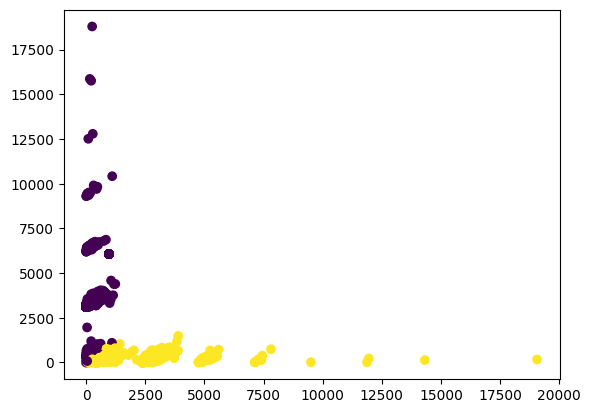

In [55]:
import seaborn as sns
plt.scatter(new_df['pos'],new_df['neg'],c=new_df['label'])

working with test data

In [56]:
test_df = pd.DataFrame()

In [57]:
test_df['processed_tweet'] = X_test.reset_index()[0].apply(process_tweet)

In [58]:
test_df['pos'] = test_df['processed_tweet'].apply(freq_func).apply(lambda x:x[0])

In [59]:
test_df['neg'] = test_df['processed_tweet'].apply(freq_func).apply(lambda x:x[1])

In [60]:
test_df['label'] = y_test.reset_index(drop=True)

In [61]:
test_df

,processed_tweet,pos,neg,label
0,"[love, feel, emm, think, :(]",338,3365,0
1,"[thank, guy, :)]",2794,108,1
2,"[love, lord, better, life, :), <3]",2804,171,1
3,"[yeah, better, use, offici, account, :), like,...",2656,281,1
4,"[ok, good, night, wish, troy, ugli, met, today...",2870,387,1
...,...,...,...,...
3295,"[girl, know, hold, racket, :)]",2511,125,1
3296,"[follow, pl, :(]",266,3307,0
3297,"[that', goat, mino]",46,44,0
3298,"[snapchat, shirleycam, snapchat, hornykik, dmm...",61,3225,0


In [62]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = sc.fit_transform(new_df[['pos','neg']].values)
x_test_scaled = sc.transform(test_df[['pos','neg']].values)

In [63]:
from sklearn.linear_model import LogisticRegression
LR = LogisticRegression()
LR.fit(x_train_scaled,y_train)
y_pred = LR.predict(x_test_scaled)

In [64]:
from sklearn.metrics import accuracy_score
accuracy_score(y_pred,y_test)

0.9903030303030304

In [65]:
import joblib
joblib.dump(LR,"model.pkl")
joblib.dump(sc,'scale.pkl')

['scale.pkl']